
# Cybersecurity Incidents and Economic Factors in US States (2014–2025)

**Objective:** Explore relationships between documented cybersecurity incidents and economic conditions across 50 US states.

**Sources:** [UMD](../01_umd_usa.ipynb) | [Economic factors](04_economic_factors.ipynb)



## 1. Data preparation and normalization

Documented cybersecurity incidents from the UMD dataset are aggregated by US state and year (2014–2025) and merged with economic indicators from BEA and BLS.

Two normalized incident rates are calculated:

- **Population-adjusted rate:** incidents per 100,000 residents.
- **Establishment-adjusted rate:** incidents per 10,000 business establishments.

$$
R_{\mathrm{pop}} = \frac{N_{\mathrm{incidents}}}{P} \times 100{,}000
$$

$$
R_{\mathrm{est}} = \frac{N_{\mathrm{incidents}}}{E} \times 10{,}000
$$

Here, $P$ denotes population and $E$ the number of business establishments. The population-adjusted rate is the primary outcome; the establishment-adjusted rate is used for descriptive comparisons.


In [26]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

import numpy as np
from scipy.optimize import minimize
from scipy.special import gammaln
from scipy.stats import pearsonr, shapiro, linregress, norm, spearmanr



In [27]:
PROJECT_ROOT = Path.cwd().resolve().parents[1]
FIGURES_DIR = PROJECT_ROOT / "figures/economic/combined"
STATIC_DIR = FIGURES_DIR / "static"
INTERACTIVE_DIR = FIGURES_DIR / "interactive"

STATIC_DIR.mkdir(parents=True, exist_ok=True)
INTERACTIVE_DIR.mkdir(parents=True, exist_ok=True)


In [28]:
umd = pd.read_csv(
    PROJECT_ROOT / "data/processed/umd_usa/umd_usa_deduplicated_consolidated.csv"
)

economic = pd.read_csv(
    PROJECT_ROOT / "data/processed/economic/combined/usa_state_economic_factors_2014_2025.csv",
    dtype={"state_fips": str}
)

overview = pd.DataFrame({
    "Dataset": ["UMD incidents", "Economic factors"],
    "Rows": [len(umd), len(economic)],
    "Columns": [umd.shape[1], economic.shape[1]],
    "First year": [umd["year"].min(), economic["year"].min()],
    "Last year": [umd["year"].max(), economic["year"].max()]
})

display(overview)


,Dataset,Rows,Columns,First year,Last year
0,UMD incidents,8203,49,2014,2026
1,Economic factors,600,23,2014,2025


In [29]:
# Restrict incidents to the economic panel period
umd_period = umd.loc[umd["year"].between(2014, 2025)].copy()

# Identify incidents assigned to one of the 50 states
valid_states = set(economic["state"].unique())
umd_period["matched_state"] = umd_period["state"].isin(valid_states)

coverage = pd.DataFrame({
    "Category": ["Matched US states", "Other / unknown locations", "Total"],
    "Incidents": [
        umd_period["matched_state"].sum(),
        (~umd_period["matched_state"]).sum(),
        len(umd_period)
    ]
})

coverage["Share (%)"] = (
    coverage["Incidents"] / len(umd_period) * 100
).round(2)

display(coverage)


,Category,Incidents,Share (%)
0,Matched US states,6195,79.51
1,Other / unknown locations,1596,20.49
2,Total,7791,100.00


In [30]:

unmatched = (
    umd_period.loc[~umd_period["matched_state"]]
    .groupby("state", dropna=False)
    .size()
    .reset_index(name="incidents")
    .sort_values("incidents", ascending=False)
)

unmatched["share_pct"] = (
    unmatched["incidents"] / len(umd_period) * 100
).round(2)

display(unmatched)


,state,incidents,share_pct
2,Undetermined,1395,17.91
4,Washington D.C.,153,1.96
1,Puerto Rico,16,0.21
6,NaN,15,0.19
5,undetermined,8,0.10
3,Virgin Islands,7,0.09
0,Guam,2,0.03



The consolidated UMD dataset contains 7,791 unique incident records for 2014–2025. Of these, 6,195 (79.51%) are assigned to the 50 US states. The remaining records are excluded due to unknown locations, Washington D.C., or US territories.


In [31]:
# Count documented incidents by state and year
annual_incidents = (
    umd_period.loc[umd_period["matched_state"]]
    .groupby(["state", "year"])
    .size()
    .reset_index(name="incident_count")
)

# Preserve all 50 states across all 12 years
panel = economic.merge(
    annual_incidents,
    on=["state", "year"],
    how="left",
    validate="one_to_one"
)

panel["incident_count"] = panel["incident_count"].fillna(0).astype(int)

# Calculate normalized incident rates
panel["incidents_per_100k"] = (
    panel["incident_count"] / panel["population"] * 100_000
)

panel["incidents_per_10k_establishments"] = (
    panel["incident_count"] / panel["qcew_establishments"] * 10_000
)

print(f"State-year observations: {len(panel)}")
print(f"Total matched incidents: {panel['incident_count'].sum():,}")
print(f"Missing normalized rates: {panel[['incidents_per_100k', 'incidents_per_10k_establishments']].isna().sum().sum()}")

display(panel[[
    "state", "year", "incident_count", "population",
    "qcew_establishments", "incidents_per_100k",
    "incidents_per_10k_establishments"
]].head())


State-year observations: 600
Total matched incidents: 6,195
Missing normalized rates: 0


,state,year,incident_count,population,qcew_establishments,incidents_per_100k,incidents_per_10k_establishments
0,Alabama,2014,1,4887757.0,117452,0.020459,0.085141
1,Alabama,2015,3,4909177.0,119251,0.061110,0.251570
2,Alabama,2016,0,4931579.0,122310,0.000000,0.000000
3,Alabama,2017,2,4953096.0,124881,0.040379,0.160152
4,Alabama,2018,6,4977088.0,127260,0.120552,0.471476



The integrated dataset contains 600 state-year observations (50 states × 12 years) and 6,195 documented incidents. Both normalized incident rates are available for all observations.


In [32]:
output_dir = PROJECT_ROOT / "data/processed/economic/combined"
output_path = output_dir / "usa_state_incidents_economic_2014_2025.csv"

panel.to_csv(output_path, index=False)

print(f"Saved: {output_path.relative_to(PROJECT_ROOT)}")


Saved: data\processed\economic\combined\usa_state_incidents_economic_2014_2025.csv



## 2. Geographic and temporal patterns

**Q1. Which US states have the highest population-adjusted cybersecurity incident rates, and how do their rankings change over time?**

Annual state rankings are based on documented incidents per 100,000 residents rather than absolute incident counts.


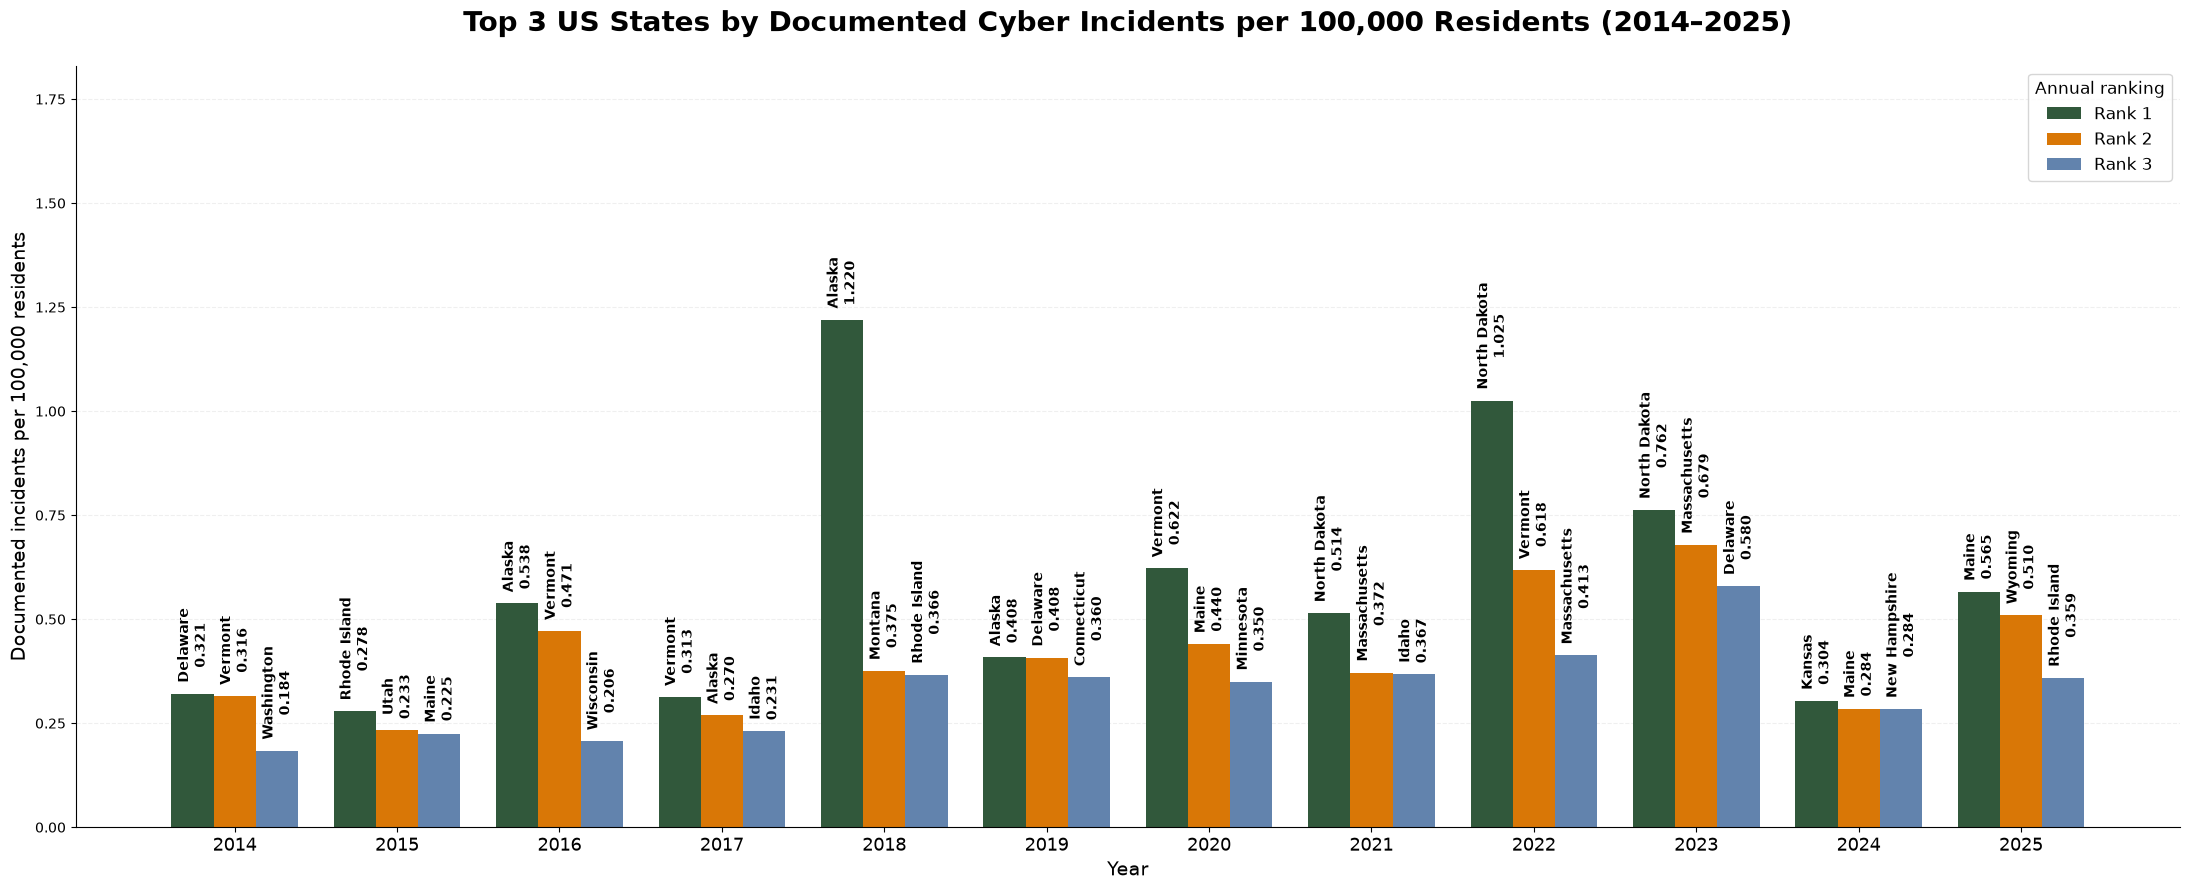

In [33]:

top3_population = (
    panel.sort_values(
        ["year", "incidents_per_100k"],
        ascending=[True, False]
    )
    .groupby("year")
    .head(3)
    .copy()
)

top3_population["rank"] = (
    top3_population.groupby("year").cumcount() + 1
)


rank_colors = {
    1: "#31583B",
    2: "#D97706",
    3: "#6283AD"
}

fig, ax = plt.subplots(figsize=(22, 9))

years = sorted(top3_population["year"].unique())
bar_width = 0.26

for rank in (1, 2, 3):
    subset = top3_population[top3_population["rank"] == rank]
    positions = [
        years.index(y) + (rank - 2) * bar_width
        for y in subset["year"]
    ]

    bars = ax.bar(
        positions,
        subset["incidents_per_100k"],
        width=bar_width,
        color=rank_colors[rank],
        label=f"Rank {rank}"
    )

    for bar, (_, record) in zip(bars, subset.iterrows()):
        ax.annotate(
            f"{record['state']}\n{record['incidents_per_100k']:.3f}",
            xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 8),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold",
            rotation=90
        )

ax.set_xticks(range(len(years)))
ax.set_xticklabels(years, fontsize=13)

ax.set_ylabel("Documented incidents per 100,000 residents", fontsize=14)
ax.set_xlabel("Year", fontsize=14)

ax.set_title(
    "Top 3 US States by Documented Cyber Incidents per 100,000 Residents (2014–2025)",
    fontsize=20,
    fontweight="bold",
    pad=25
)

ax.legend(title="Annual ranking", fontsize=12, title_fontsize=12)
ax.set_ylim(0, top3_population["incidents_per_100k"].max() * 1.5)
ax.grid(axis="y", linestyle="--", alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()


fig.savefig(
    STATIC_DIR / "05_01_top3_states_per_100k.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [34]:
# State FIPS to USPS abbreviations
state_codes = {
    "01": "AL", "02": "AK", "04": "AZ", "05": "AR", "06": "CA",
    "08": "CO", "09": "CT", "10": "DE", "12": "FL", "13": "GA",
    "15": "HI", "16": "ID", "17": "IL", "18": "IN", "19": "IA",
    "20": "KS", "21": "KY", "22": "LA", "23": "ME", "24": "MD",
    "25": "MA", "26": "MI", "27": "MN", "28": "MS", "29": "MO",
    "30": "MT", "31": "NE", "32": "NV", "33": "NH", "34": "NJ",
    "35": "NM", "36": "NY", "37": "NC", "38": "ND", "39": "OH",
    "40": "OK", "41": "OR", "42": "PA", "44": "RI", "45": "SC",
    "46": "SD", "47": "TN", "48": "TX", "49": "UT", "50": "VT",
    "51": "VA", "53": "WA", "54": "WV", "55": "WI", "56": "WY"
}

map_data = panel.copy()
map_data["state_code"] = map_data["state_fips"].str.zfill(2).map(state_codes)
map_data["year_label"] = map_data["year"].astype(str)

fig = px.choropleth(
    map_data,
    locations="state_code",
    locationmode="USA-states",
    scope="usa",
    color="incidents_per_100k",
    animation_frame="year_label",
    hover_name="state",
    hover_data={
        "state_code": False,
        "year_label": False,
        "incident_count": True,
        "population": ":,",
        "incidents_per_100k": ":.3f"
    },
    color_continuous_scale="YlGn",
    range_color=(0, map_data["incidents_per_100k"].max()),
    labels={"incidents_per_100k": "Incidents per 100k"},
    title="Documented Cyber Incidents per 100,000 Residents by State (2014–2025)"
)

fig.update_layout(
    title=dict(font=dict(size=21, family="Arial Black")),
    height=700,
    margin=dict(l=20, r=20, t=80, b=30),
    coloraxis_colorbar=dict(title="Incidents<br>per 100k")
)

fig.show()

fig.write_html(
    INTERACTIVE_DIR / "05_02_incidents_per_100k_map.html",
    include_plotlyjs=True
)



### Incident rates relative to business establishments

State rankings are recalculated using documented incidents per 10,000 business establishments instead of population. This provides an alternative perspective based on the scale of business activity.


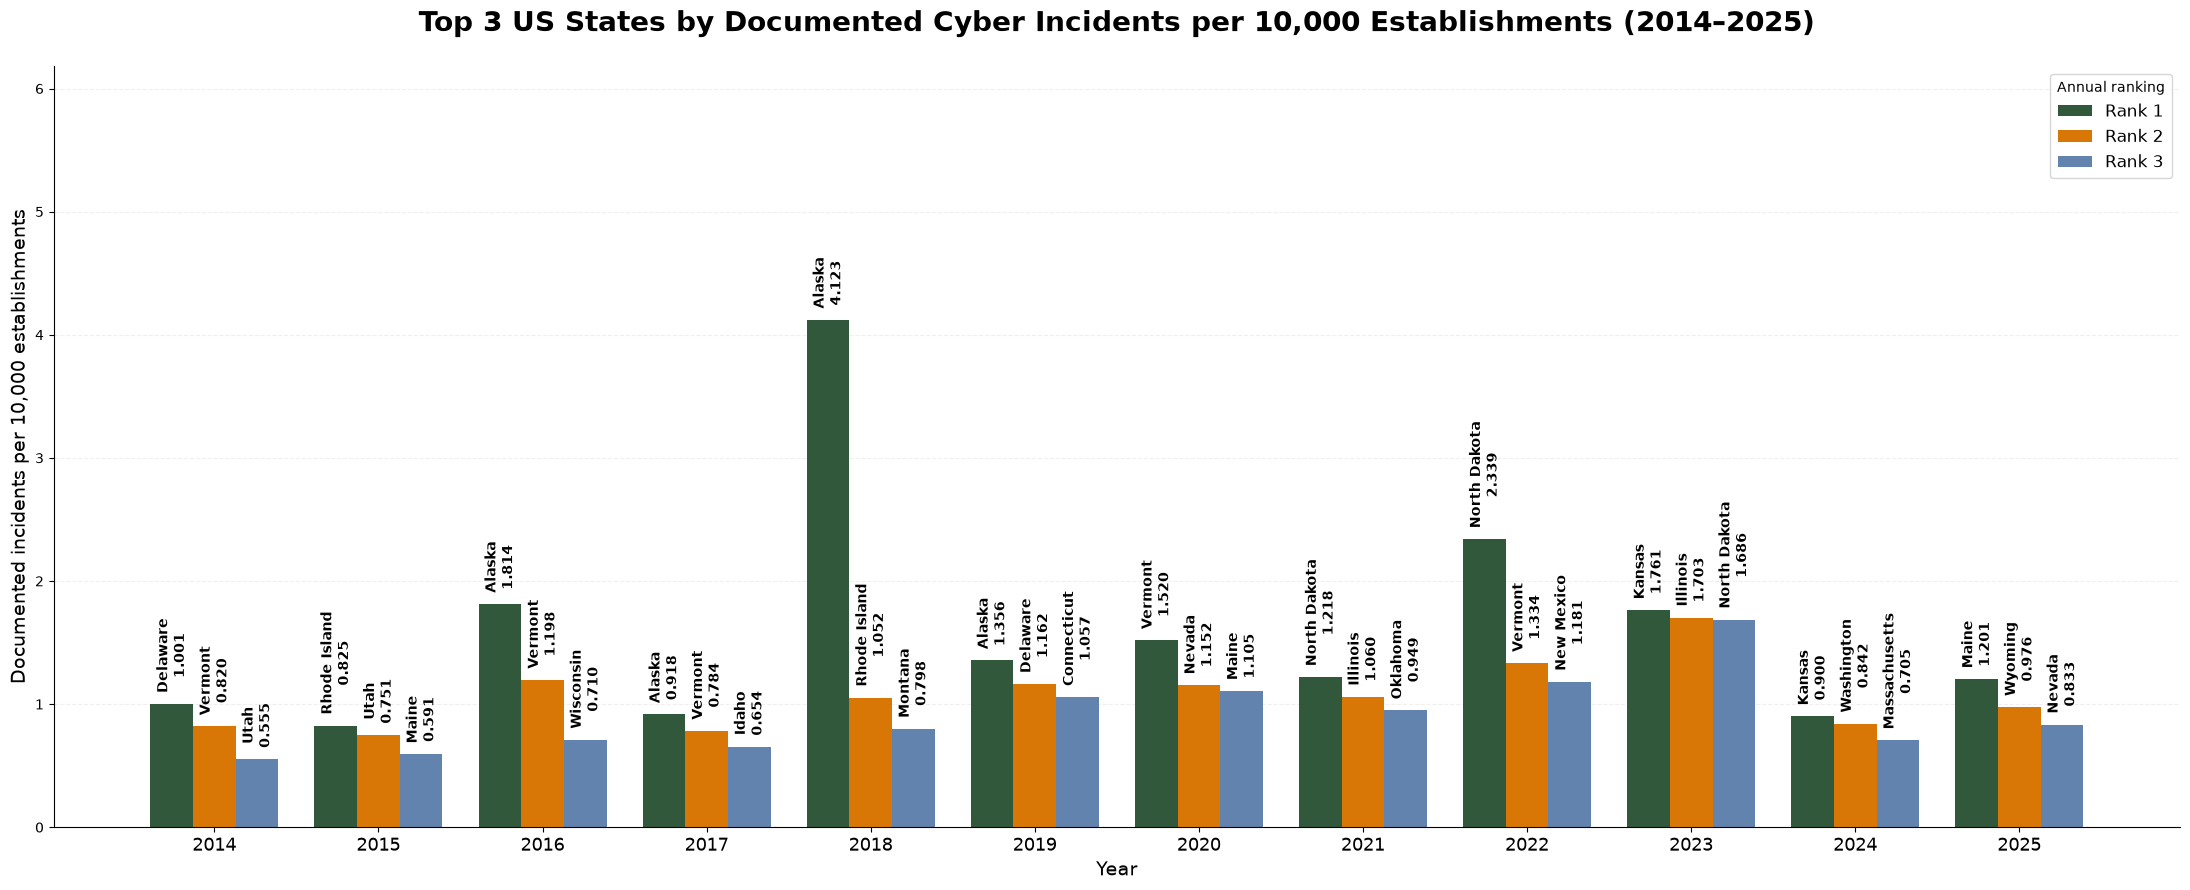

In [35]:
top3_establishments = (
    panel.sort_values(
        ["year", "incidents_per_10k_establishments"],
        ascending=[True, False]
    )
    .groupby("year")
    .head(3)
    .copy()
)

top3_establishments["rank"] = (
    top3_establishments.groupby("year").cumcount() + 1
)

rank_colors = {
    1: "#31583B",
    2: "#D97706",
    3: "#6283AD"
}

fig, ax = plt.subplots(figsize=(22, 9))
years = sorted(top3_establishments["year"].unique())
bar_width = 0.26

for rank in (1, 2, 3):
    subset = top3_establishments[top3_establishments["rank"] == rank]
    positions = [
        years.index(y) + (rank - 2) * bar_width
        for y in subset["year"]
    ]

    bars = ax.bar(
        positions,
        subset["incidents_per_10k_establishments"],
        width=bar_width,
        color=rank_colors[rank],
        label=f"Rank {rank}"
    )

    for bar, (_, record) in zip(bars, subset.iterrows()):
        ax.annotate(
            f"{record['state']}\n{record['incidents_per_10k_establishments']:.3f}",
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 8),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold",
            rotation=90
        )

ax.set_xticks(range(len(years)), years, fontsize=13)
ax.set_xlabel("Year", fontsize=14)
ax.set_ylabel("Documented incidents per 10,000 establishments", fontsize=14)

ax.set_title(
    "Top 3 US States by Documented Cyber Incidents per 10,000 Establishments (2014–2025)",
    fontsize=20,
    fontweight="bold",
    pad=25
)

ax.legend(title="Annual ranking", fontsize=12)
ax.set_ylim(
    0,
    top3_establishments["incidents_per_10k_establishments"].max() * 1.5
)
ax.grid(axis="y", linestyle="--", alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()

fig.savefig(
    STATIC_DIR / "05_03_top3_states_per_10k_establishments.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



Normalizing incidents by business establishments produces rankings broadly similar to population-based normalization. Alaska, Vermont, and North Dakota remain prominent, indicating that both rates are sensitive to small incident counts and differences in state size.



### Empirical Bayes smoothing

A Poisson–Gamma empirical Bayes model is applied to stabilize population-adjusted incident rates across all 50 states. Incident counts and population exposure are aggregated over 2014–2025.

The posterior mean rate is:

$$
\hat{r}_i^{EB} = \frac{N_i+\alpha}{E_i+\beta},
\qquad
E_i = \frac{\sum_{t=2014}^{2025} P_{it}}{100{,}000}
$$

Here, $N_i$ is the total documented incident count, $E_i$ is population exposure in units of 100,000 person-years, and $\alpha,\beta$ are estimated from the data.

The method reduces instability in rates based on limited observations without excluding smaller states.


In [36]:
# Aggregate incident counts and population exposure over 2014–2025
eb_states = (
    panel.groupby("state", as_index=False)
    .agg(
        incidents=("incident_count", "sum"),
        population_exposure=("population", "sum")
    )
)

eb_states["exposure"] = eb_states["population_exposure"] / 100_000
eb_states["raw_rate"] = eb_states["incidents"] / eb_states["exposure"]

counts = eb_states["incidents"].to_numpy(dtype=float)
exposure = eb_states["exposure"].to_numpy(dtype=float)

# Gamma-Poisson marginal negative log-likelihood
def negative_log_likelihood(log_params):
    alpha, beta = np.exp(log_params)

    log_likelihood = (
        gammaln(counts + alpha)
        - gammaln(alpha)
        - gammaln(counts + 1)
        + alpha * (np.log(beta) - np.log(beta + exposure))
        + counts * (np.log(exposure) - np.log(beta + exposure))
    )

    return -log_likelihood.sum()

overall_rate = counts.sum() / exposure.sum()
initial_alpha = 2.0
initial_beta = initial_alpha / overall_rate

result = minimize(
    negative_log_likelihood,
    x0=np.log([initial_alpha, initial_beta]),
    method="L-BFGS-B",
    bounds=[(-12, 14), (-12, 14)]
)

if not result.success:
    raise RuntimeError(f"EB estimation failed: {result.message}")

alpha, beta = np.exp(result.x)

# Posterior mean incident rate per 100,000 residents per year
eb_states["eb_rate"] = (
    (eb_states["incidents"] + alpha)
    / (eb_states["exposure"] + beta)
)

eb_states["raw_rank"] = (
    eb_states["raw_rate"].rank(ascending=False, method="min").astype(int)
)
eb_states["eb_rank"] = (
    eb_states["eb_rate"].rank(ascending=False, method="min").astype(int)
)

print(f"Prior mean rate: {alpha / beta:.4f}")
print(f"Estimated alpha: {alpha:.4f}")
print(f"Estimated beta: {beta:.4f}")

display(
    eb_states.sort_values("eb_rank")[
        ["state", "incidents", "raw_rate", "eb_rate",
         "raw_rank", "eb_rank"]
    ].head(15).round(4)
)


# Export state-level Empirical Bayes results
eb_states.to_csv(
    output_dir / "usa_state_eb_smoothed_rates_2014_2025.csv",
    index=False
)


Prior mean rate: 0.1579
Estimated alpha: 20.4935
Estimated beta: 129.8125


,state,incidents,raw_rate,eb_rate,raw_rank,eb_rank
20,Massachusetts,217,0.2585,0.2450,4,1
18,Maine,44,0.2679,0.2193,3,2
1,Alaska,26,0.2940,0.2130,2,3
44,Vermont,23,0.2985,0.2103,1,4
33,North Dakota,24,0.2579,0.1996,5,5
46,Washington,187,0.2050,0.1991,8,6
22,Minnesota,140,0.2058,0.1981,7,7
31,New York,459,0.1910,0.1893,9,8
4,California,881,0.1870,0.1862,13,9
7,Delaware,25,0.2099,0.1828,6,10


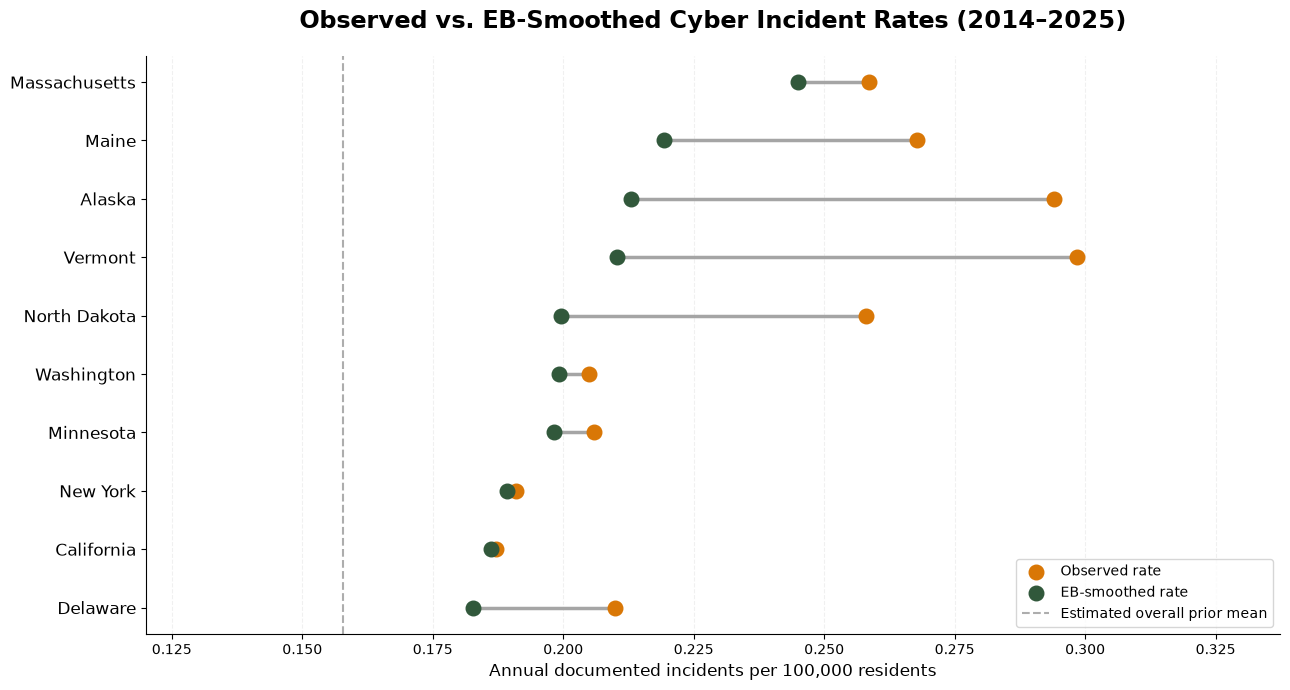

In [37]:

comparison = (
    eb_states.nlargest(10, "eb_rate")
    .sort_values("eb_rate")
)

fig, ax = plt.subplots(figsize=(13, 7))
y = np.arange(len(comparison))

# Connect observed and smoothed rates
for i, record in enumerate(comparison.itertuples()):
    ax.plot(
        [record.eb_rate, record.raw_rate],
        [i, i],
        color="#A5A5A5",
        linewidth=2.5,
        zorder=1
    )

ax.scatter(
    comparison["raw_rate"], y,
    s=110, color="#D97706",
    label="Observed rate", zorder=3
)

ax.scatter(
    comparison["eb_rate"], y,
    s=110, color="#31583B",
    label="EB-smoothed rate", zorder=3
)

ax.set_yticks(y)
ax.set_yticklabels(comparison["state"], fontsize=12)

ax.set_xlabel(
    "Annual documented incidents per 100,000 residents",
    fontsize=12
)
ax.set_title(
    "Observed vs. EB-Smoothed Cyber Incident Rates (2014–2025)",
    fontsize=17, fontweight="bold", pad=20
)

ax.axvline(
    alpha / beta,
    linestyle="--",
    color="#777777",
    alpha=0.6,
    label="Estimated overall prior mean"
)

ax.legend(loc="lower right", fontsize=10)
ax.grid(axis="x", linestyle="--", alpha=0.18)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlim(0.12, max(comparison["raw_rate"].max(), comparison["eb_rate"].max()) * 1.13)

plt.tight_layout()

fig.savefig(
    STATIC_DIR / "05_07_raw_vs_eb_smoothed_rates.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



Empirical Bayes smoothing reduces extreme observed rates, particularly in states with limited incident counts. Massachusetts becomes the highest-ranked state, while Vermont drops from first to fourth. The results demonstrate the sensitivity of state rankings to statistical uncertainty.



### Overall EB-smoothed state rankings (2014–2025)

States are ranked by their Empirical Bayes-smoothed incident rates over the full study period. Absolute incident counts are included to provide context for the adjusted rankings.


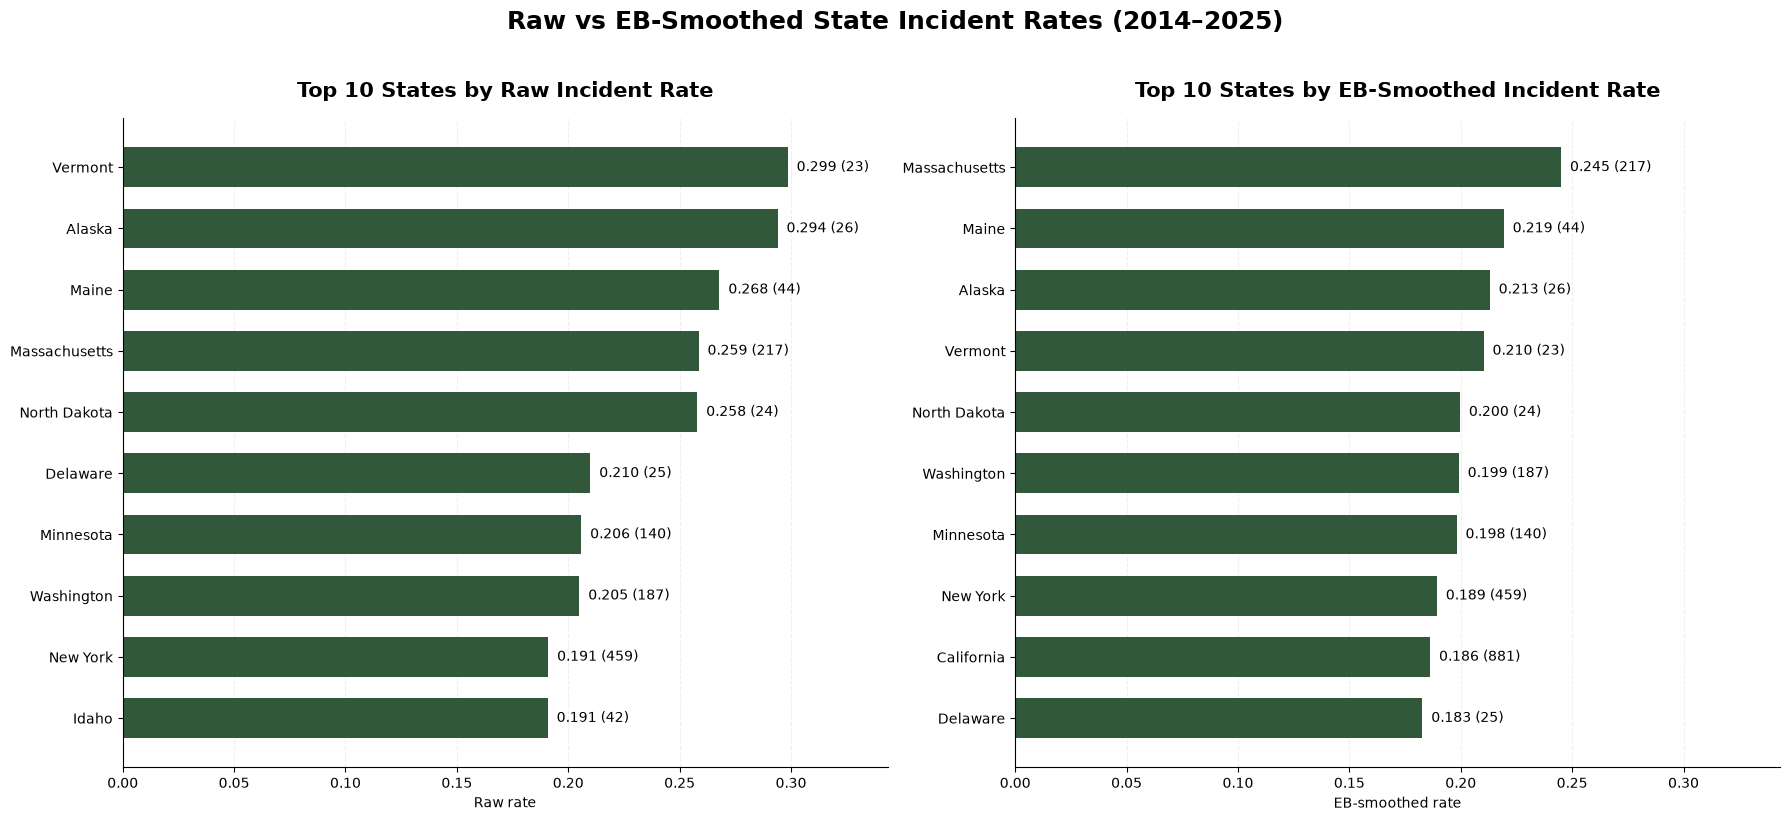

In [38]:
top10_raw = eb_states.nlargest(10, "raw_rate").sort_values("raw_rate")
top10_eb = eb_states.nlargest(10, "eb_rate").sort_values("eb_rate")

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# --- Left: raw rates ---
bars_raw = axes[0].barh(
    top10_raw["state"],
    top10_raw["raw_rate"],
    color="#31583B",
    height=0.65
)

for bar, record in zip(bars_raw, top10_raw.itertuples()):
    axes[0].text(
        bar.get_width() + 0.004,
        bar.get_y() + bar.get_height() / 2,
        f"{record.raw_rate:.3f} ({record.incidents})",
        va="center",
        fontsize=10
    )

axes[0].set_title(
    "Top 10 States by Raw Incident Rate",
    fontsize=15,
    fontweight="bold",
    pad=15
)
axes[0].set_xlabel("Raw rate")
axes[0].grid(axis="x", linestyle="--", alpha=0.2)
axes[0].set_axisbelow(True)
axes[0].spines[["top", "right"]].set_visible(False)

# --- Right: EB-smoothed rates ---
bars_eb = axes[1].barh(
    top10_eb["state"],
    top10_eb["eb_rate"],
    color="#31583B",
    height=0.65
)

for bar, record in zip(bars_eb, top10_eb.itertuples()):
    axes[1].text(
        bar.get_width() + 0.004,
        bar.get_y() + bar.get_height() / 2,
        f"{record.eb_rate:.3f} ({record.incidents})",
        va="center",
        fontsize=10
    )

axes[1].set_title(
    "Top 10 States by EB-Smoothed Incident Rate",
    fontsize=15,
    fontweight="bold",
    pad=15
)
axes[1].set_xlabel("EB-smoothed rate")
axes[1].grid(axis="x", linestyle="--", alpha=0.2)
axes[1].set_axisbelow(True)
axes[1].spines[["top", "right"]].set_visible(False)

plt.suptitle(
    "Raw vs EB-Smoothed State Incident Rates (2014–2025)",
    fontsize=18,
    fontweight="bold",
    y=1.02
)
common_max = max(
    top10_raw["raw_rate"].max(),
    top10_eb["eb_rate"].max()
) * 1.15

for ax in axes:
    ax.set_xlim(0, common_max)

plt.tight_layout()

fig.savefig(
    STATIC_DIR / "05_09_raw_vs_eb_smoothed_state_rates.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Empirical Bayes smoothing changes the ranking of states by reducing the influence of statistically unstable rates. Vermont drops from first to fourth place, while Massachusetts rises from fourth to first. Larger states generally show smaller adjustments due to greater population exposure and more documented incidents.



## 3. Economic development and cyber incidents

**Q3. Is GDP per capita associated with population-adjusted cybersecurity incident rates?**

GDP per capita is used as an indicator of economic development. Its association with documented incidents per 100,000 residents is examined across the 50 US states.


In [39]:

scatter_data = panel.copy()
scatter_data["gdp_per_capita_1000"] = scatter_data["gdp_per_capita"] / 1_000
scatter_data["year_label"] = scatter_data["year"].astype(str)

fig = px.scatter(
    scatter_data,
    x="gdp_per_capita_1000",
    y="incidents_per_100k",
    animation_frame="year_label",
    hover_name="state",
    hover_data={
        "year_label": False,
        "gdp_per_capita_1000": ":.1f",
        "incidents_per_100k": ":.3f",
        "incident_count": True,
        "population": ":,"
    },
    color_discrete_sequence=["#31583B"],
    range_x=[
        scatter_data["gdp_per_capita_1000"].min() * 0.9,
        scatter_data["gdp_per_capita_1000"].max() * 1.05
    ],
    range_y=[
        0,
        scatter_data["incidents_per_100k"].max() * 1.1
    ],
    labels={
        "gdp_per_capita_1000": "GDP per capita (thousand USD)",
        "incidents_per_100k": "Documented incidents per 100,000 residents"
    },
    title="GDP per Capita vs. Documented Cyber Incident Rates (2014–2025)"
)

fig.update_traces(marker=dict(size=11, opacity=0.8))

fig.update_layout(
    title=dict(font=dict(size=21, family="Arial Black")),
    height=700,
    margin=dict(l=70, r=40, t=90, b=90),
    plot_bgcolor="white",
    xaxis=dict(showgrid=True, gridcolor="#EEEEEE"),
    yaxis=dict(showgrid=True, gridcolor="#EEEEEE")
)

fig.show()

fig.write_html(
    INTERACTIVE_DIR / "05_10_gdp_per_capita_vs_incident_rates.html",
    include_plotlyjs=True
)



### Distribution assessment (2023)

The distributions of GDP per capita and documented cyber incident rates per 100,000 residents are compared with fitted normal distributions. This assessment helps identify skewness and outliers before selecting an appropriate correlation method.


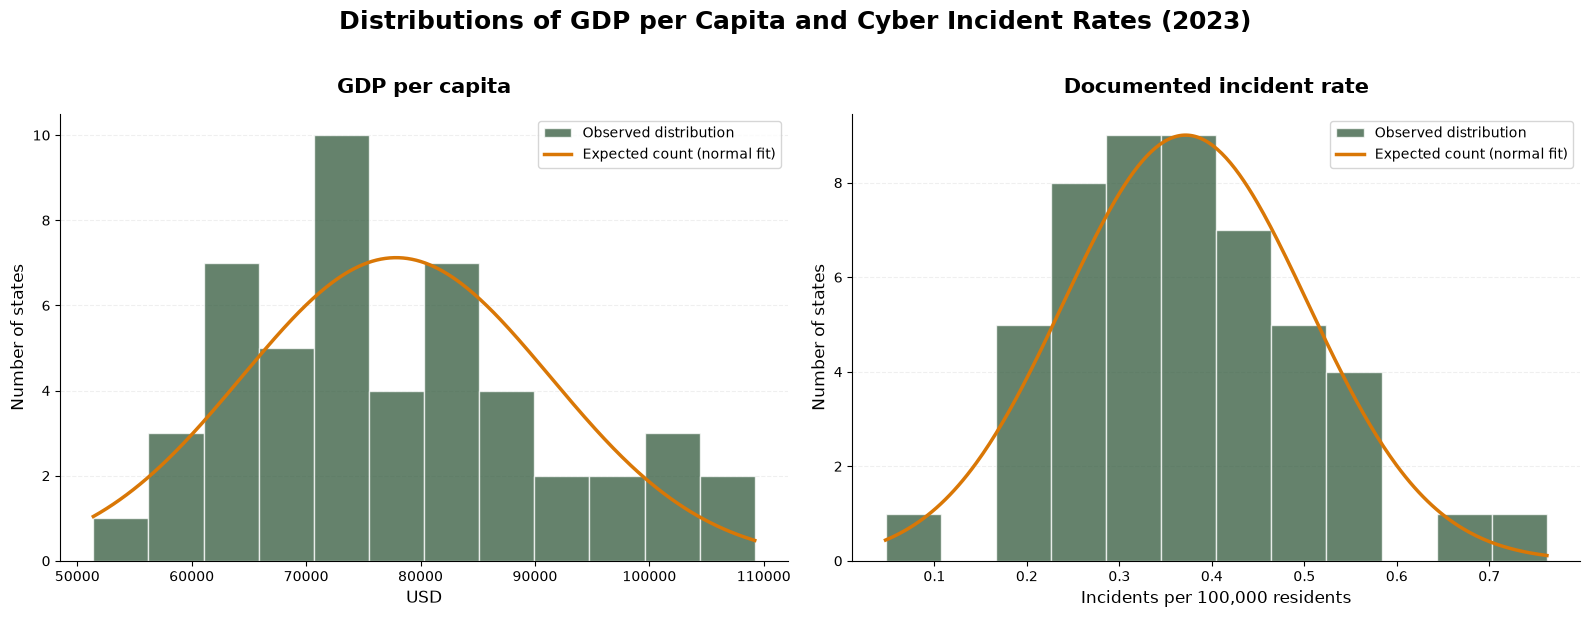

In [40]:

data_2023 = panel.loc[panel["year"] == 2023].copy()

variables = [
    ("gdp_per_capita", "GDP per capita", "USD"),
    ("incidents_per_100k", "Documented incident rate",
     "Incidents per 100,000 residents")
]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, (column, title, xlabel) in zip(axes, variables):
    values = data_2023[column].dropna().to_numpy()
    n_bins = 12

    # Observed counts
    counts, edges, _ = ax.hist(
        values,
        bins=n_bins,
        density=False,
        color="#31583B",
        alpha=0.75,
        edgecolor="white",
        label="Observed distribution"
    )

    # Fitted normal distribution scaled to expected state counts
    mu, sigma = norm.fit(values)
    x = np.linspace(edges[0], edges[-1], 300)
    bin_width = edges[1] - edges[0]

    expected_counts = norm.pdf(x, mu, sigma) * len(values) * bin_width

    ax.plot(
        x,
        expected_counts,
        color="#D97706",
        linewidth=2.5,
        label="Expected count (normal fit)"
    )

    ax.set_title(title, fontsize=15, fontweight="bold", pad=15)
    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_ylabel("Number of states", fontsize=12)

    ax.grid(axis="y", linestyle="--", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(fontsize=10)

fig.suptitle(
    "Distributions of GDP per Capita and Cyber Incident Rates (2023)",
    fontsize=18,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()

fig.savefig(
    STATIC_DIR / "05_11_variable_distributions_2023.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



### Pearson correlation and normality assessment (2023)

Pearson correlation measures the linear association between GDP per capita and population-adjusted cyber incident rates. Shapiro–Wilk tests are applied to both variables and the regression residuals to assess deviations from normality.


Pearson r = 0.5236, p = 0.000096

Shapiro-Wilk normality tests:
GDP per capita: W = 0.9725, p = 0.2919 — Normality not rejected
Incident rate: W = 0.9768, p = 0.4260 — Normality not rejected
Regression residuals: W = 0.9803, p = 0.5654 — Normality not rejected


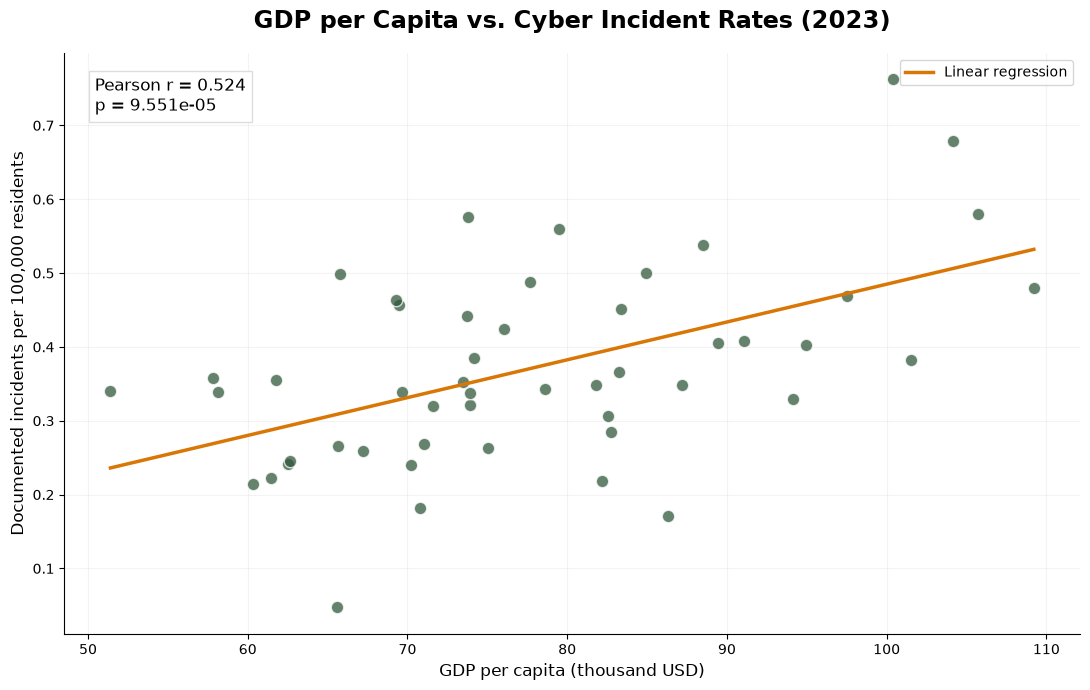

In [41]:
data_2023 = panel.loc[panel["year"] == 2023].copy()

x = data_2023["gdp_per_capita"].to_numpy() / 1_000
y = data_2023["incidents_per_100k"].to_numpy()

# Pearson correlation and linear regression
r, p = pearsonr(x, y)
regression = linregress(x, y)
predicted = regression.intercept + regression.slope * x
residuals = y - predicted

# Shapiro-Wilk normality tests
tests = {
    "GDP per capita": shapiro(x),
    "Incident rate": shapiro(y),
    "Regression residuals": shapiro(residuals)
}

print(f"Pearson r = {r:.4f}, p = {p:.6f}\n")
print("Shapiro-Wilk normality tests:")

for name, result in tests.items():
    print(
        f"{name}: W = {result.statistic:.4f}, "
        f"p = {result.pvalue:.4f} — "
        f"{'Reject normality' if result.pvalue < 0.05 else 'Normality not rejected'}"
    )

# Scatter plot with fitted regression line
fig, ax = plt.subplots(figsize=(11, 7))

ax.scatter(
    x, y,
    s=80, color="#31583B",
    alpha=0.75, edgecolor="white"
)

x_line = np.linspace(x.min(), x.max(), 200)
y_line = regression.intercept + regression.slope * x_line

ax.plot(
    x_line, y_line,
    color="#D97706",
    linewidth=2.5,
    label="Linear regression"
)

ax.text(
    0.03, 0.96,
    f"Pearson r = {r:.3f}\np = {p:.4g}",
    transform=ax.transAxes,
    ha="left", va="top",
    fontsize=12,
    bbox=dict(facecolor="white", edgecolor="#DDDDDD")
)

ax.set_title(
    "GDP per Capita vs. Cyber Incident Rates (2023)",
    fontsize=17, fontweight="bold", pad=18
)
ax.set_xlabel("GDP per capita (thousand USD)", fontsize=12)
ax.set_ylabel("Documented incidents per 100,000 residents", fontsize=12)

ax.legend()
ax.grid(alpha=0.15)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()

fig.savefig(
    STATIC_DIR / "05_12_gdp_pearson_correlation_2023.png",
    dpi=300, bbox_inches="tight"
)

plt.show()



### Pearson and Spearman correlation comparison

Pearson and Spearman correlations are compared annually to assess the robustness of associations between GDP per capita and documented cyber incident rates. Spearman's rank correlation provides a nonparametric alternative when distributions deviate from normality.


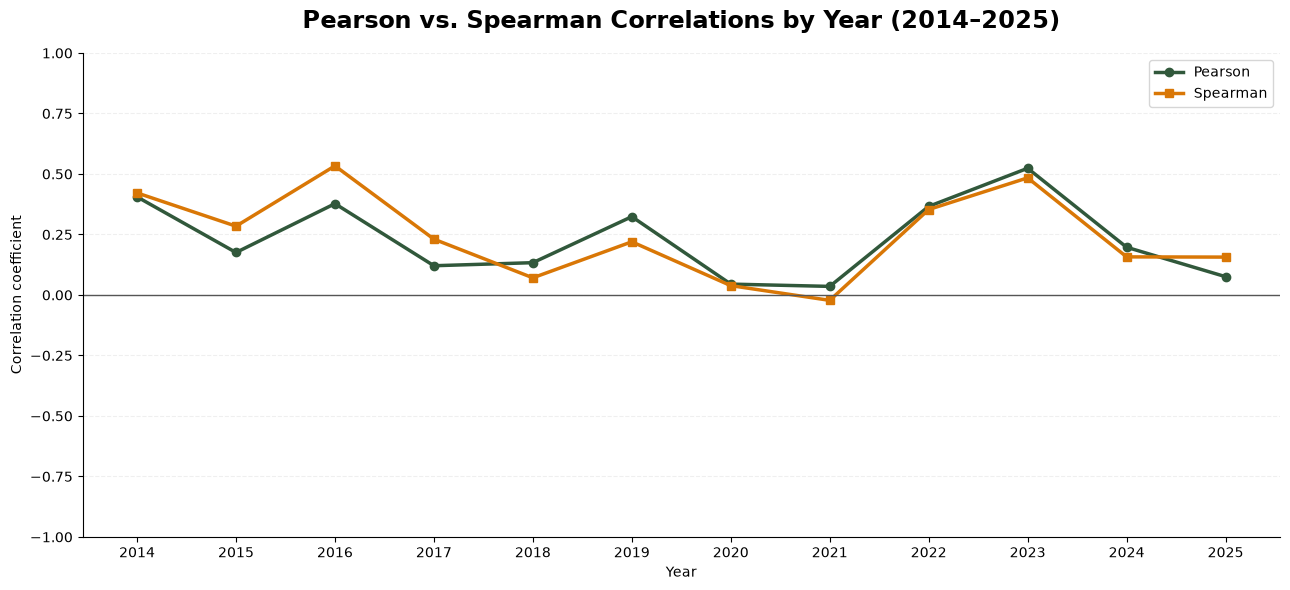

,year,pearson_r,pearson_p,spearman_r,spearman_p
0,2014,0.4055,0.0035,0.4218,0.0023
1,2015,0.1755,0.2227,0.2843,0.0454
2,2016,0.3773,0.0069,0.5336,0.0001
3,2017,0.1208,0.4033,0.2307,0.1071
4,2018,0.1335,0.3554,0.0709,0.6247
5,2019,0.3236,0.0219,0.2198,0.1251
6,2020,0.0449,0.7568,0.0387,0.7898
7,2021,0.0355,0.8069,-0.0223,0.8779
8,2022,0.3661,0.0089,0.3532,0.0119
9,2023,0.5236,0.0001,0.4841,0.0004


In [42]:

comparison_results = []

for year, group in panel.groupby("year"):
    x = group["gdp_per_capita"]
    y = group["incidents_per_100k"]

    pearson_r, pearson_p = pearsonr(x, y)
    spearman_r, spearman_p = spearmanr(x, y)

    comparison_results.append({
        "year": year,
        "pearson_r": pearson_r,
        "pearson_p": pearson_p,
        "spearman_r": spearman_r,
        "spearman_p": spearman_p
    })

correlation_comparison = pd.DataFrame(comparison_results)

fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    correlation_comparison["year"],
    correlation_comparison["pearson_r"],
    marker="o",
    linewidth=2.5,
    color="#31583B",
    label="Pearson"
)

ax.plot(
    correlation_comparison["year"],
    correlation_comparison["spearman_r"],
    marker="s",
    linewidth=2.5,
    color="#D97706",
    label="Spearman"
)

ax.axhline(0, color="#555555", linewidth=1)
ax.set_xticks(correlation_comparison["year"])
ax.set_ylim(-1, 1)
ax.set_title(
    "Pearson vs. Spearman Correlations by Year (2014–2025)",
    fontsize=17,
    fontweight="bold",
    pad=18
)
ax.set_xlabel("Year")
ax.set_ylabel("Correlation coefficient")
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()

fig.savefig(
    STATIC_DIR / "05_14_pearson_vs_spearman_by_year.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(correlation_comparison.round(4))



## 4. Economic factors and cybersecurity incident rates

**Q4. Which economic indicators are most strongly associated with documented cyber incident rates?**

Spearman correlations are calculated across the 50 US states in 2023 to compare economic development, income, labor market conditions, and business activity.


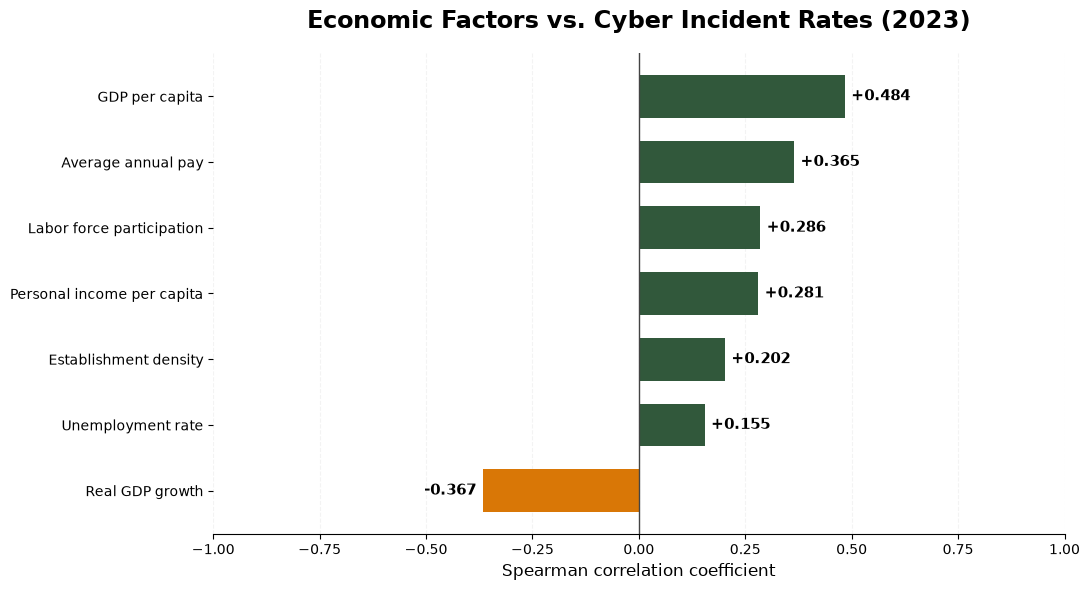

,Spearman correlation
Real GDP growth,-0.3672
Unemployment rate,0.1548
Establishment density,0.2024
Personal income per capita,0.2808
Labor force participation,0.2855
Average annual pay,0.3649
GDP per capita,0.4841


In [43]:
economic_features = {
    "gdp_per_capita": "GDP per capita",
    "personal_income_per_capita": "Personal income per capita",
    "real_gdp_growth_pct": "Real GDP growth",
    "unemployment_rate": "Unemployment rate",
    "labor_force_participation_rate": "Labor force participation",
    "establishments_per_10k": "Establishment density",
    "qcew_avg_annual_pay": "Average annual pay"
}

corr_2023 = (
    data_2023[list(economic_features) + ["incidents_per_100k"]]
    .corr(method="spearman")["incidents_per_100k"]
    .drop("incidents_per_100k")
    .rename(index=economic_features)
    .sort_values()
)

fig, ax = plt.subplots(figsize=(11, 6))

colors = [
    "#31583B" if value >= 0 else "#D97706"
    for value in corr_2023
]

bars = ax.barh(
    corr_2023.index,
    corr_2023.values,
    color=colors,
    height=0.65
)

for bar, value in zip(bars, corr_2023.values):
    ax.text(
        value + (0.015 if value >= 0 else -0.015),
        bar.get_y() + bar.get_height() / 2,
        f"{value:+.3f}",
        va="center",
        ha="left" if value >= 0 else "right",
        fontsize=11,
        fontweight="bold"
    )

ax.axvline(0, color="#444444", linewidth=1)
ax.set_xlim(-1, 1)
ax.set_xlabel("Spearman correlation coefficient", fontsize=12)
ax.set_title(
    "Economic Factors vs. Cyber Incident Rates (2023)",
    fontsize=17,
    fontweight="bold",
    pad=18
)

ax.grid(axis="x", linestyle="--", alpha=0.15)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)

plt.tight_layout()

fig.savefig(
    STATIC_DIR / "05_15_economic_factor_correlations_2023.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(corr_2023.round(4).to_frame("Spearman correlation"))



### Temporal consistency of economic associations

Annual Spearman correlations are compared across 2014–2025 to identify economic indicators with persistent or changing associations with documented cyber incident rates.


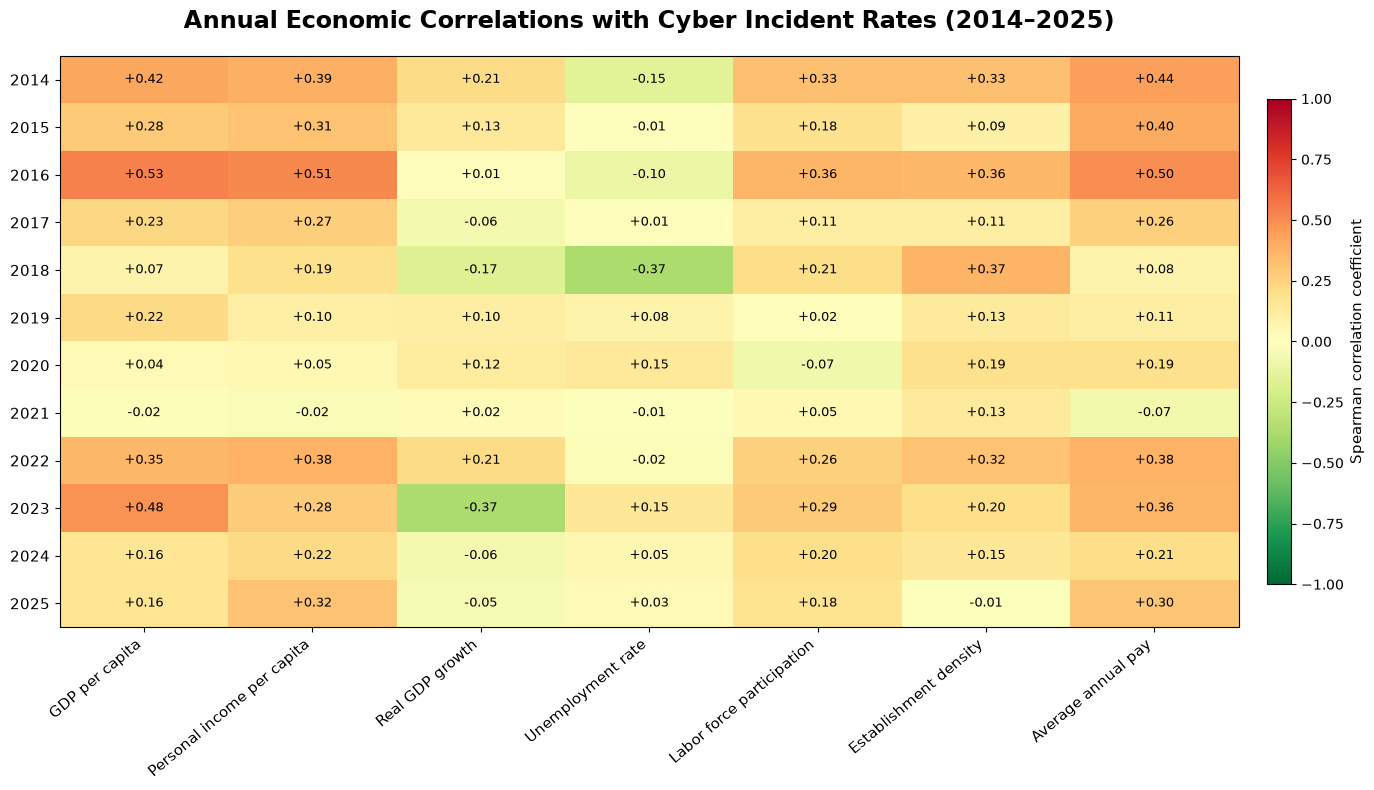

In [44]:

annual_economic_corr = []

for year, group in panel.groupby("year"):
    correlations = group[
        list(economic_features) + ["incidents_per_100k"]
    ].corr(method="spearman")["incidents_per_100k"]

    annual_economic_corr.append({
        "year": year,
        **{
            label: correlations[column]
            for column, label in economic_features.items()
        }
    })

corr_heatmap = (
    pd.DataFrame(annual_economic_corr)
    .set_index("year")
)

from matplotlib.colors import TwoSlopeNorm

fig, ax = plt.subplots(figsize=(15, 8))

im = ax.imshow(
    corr_heatmap.values,
    cmap="RdYlGn_r",
    norm=TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1),
    aspect="auto"
)

ax.set_xticks(range(len(corr_heatmap.columns)))
ax.set_xticklabels(
    corr_heatmap.columns,
    rotation=40,
    ha="right",
    fontsize=11
)

ax.set_yticks(range(len(corr_heatmap.index)))
ax.set_yticklabels(corr_heatmap.index, fontsize=11)

for i in range(len(corr_heatmap.index)):
    for j in range(len(corr_heatmap.columns)):
        value = corr_heatmap.iloc[i, j]

        ax.text(
            j, i, f"{value:+.2f}",
            ha="center", va="center",
            fontsize=9,
            color="black"
        )

ax.set_title(
    "Annual Economic Correlations with Cyber Incident Rates (2014–2025)",
    fontsize=17,
    fontweight="bold",
    pad=20
)

cbar = fig.colorbar(im, ax=ax, shrink=0.85, pad=0.02)
cbar.set_label("Spearman correlation coefficient", fontsize=11)

plt.tight_layout()

fig.savefig(
    STATIC_DIR / "05_16_annual_economic_correlations_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



### Key observations and open research questions

The correlation matrix reveals several patterns that warrant further investigation:

1. Why was real GDP growth negatively correlated with documented cyber incident rates ($r_s = -0.37$) in 2023, the year with the highest number of documented incidents?

2. Why were correlations with GDP per capita and personal income per capita close to zero in 2020–2021?

3. Did remote work, increased digital activity, changing attack targets, or shifts in incident reporting influence these relationships?

4. Why was unemployment negatively correlated with incident rates in 2018 ($r_s = -0.37$)?

5. Could differences in economic development or labor market structure explain this pattern?

6. Why do GDP per capita and average annual pay show predominantly positive associations with incident rates, while real GDP growth exhibits inconsistent relationships?

7. Could variation in digitalization, industry composition, cybersecurity maturity, or incident reporting explain why economically similar states experience different documented incident rates?

8. Why do the strengths of economic correlations fluctuate substantially between years?

9. Are these changes related to shifts in attack types, targeted sectors, or broader economic conditions?

In [45]:

# Interactive comparison of economic factors and incident rates (2023)

features = {
    "gdp_per_capita": ("GDP per capita", "USD"),
    "personal_income_per_capita": ("Personal income per capita", "USD"),
    "real_gdp_growth_pct": ("Real GDP growth", "%"),
    "unemployment_rate": ("Unemployment rate", "%"),
    "labor_force_participation_rate": ("Labor force participation", "%"),
    "establishments_per_10k": ("Establishment density", "per 10,000 residents"),
    "qcew_avg_annual_pay": ("Average annual pay", "USD")
}

plot_data = panel.loc[panel["year"] == 2023].copy()
feature_names = list(features)

fig = go.Figure()

for i, (column, (label, unit)) in enumerate(features.items()):
    r = plot_data[[column, "incidents_per_100k"]].corr(
        method="spearman"
    ).iloc[0, 1]

    fig.add_trace(
        go.Scatter(
            x=plot_data[column],
            y=plot_data["incidents_per_100k"],
            mode="markers",
            name=label,
            visible=(i == 0),
            marker=dict(
                color="#31583B",
                size=11,
                opacity=0.8,
                line=dict(color="white", width=1)
            ),
            customdata=plot_data[
                ["state", "incident_count", "population"]
            ].to_numpy(),
            hovertemplate=(
                "<b>%{customdata[0]}</b><br>"
                f"{label}: %{{x:,.2f}} {unit}<br>"
                "Incident rate: %{y:.3f} per 100,000<br>"
                "Documented incidents: %{customdata[1]}<br>"
                "Population: %{customdata[2]:,.0f}"
                "<extra></extra>"
            )
        )
    )

buttons = []

for i, (column, (label, unit)) in enumerate(features.items()):
    r = plot_data[[column, "incidents_per_100k"]].corr(
        method="spearman"
    ).iloc[0, 1]

    visible = [False] * len(feature_names)
    visible[i] = True

    buttons.append(
        dict(
            label=label,
            method="update",
            args=[
                {"visible": visible},
                {
                    "title.text": (
                        f"{label} vs. Cyber Incident Rates (2023)"
                        f"<br><sup>Spearman ρ = {r:+.3f}</sup>"
                    ),
                    "xaxis.title.text": f"{label} ({unit})"
                }
            ]
        )
    )

first_column = feature_names[0]
first_label, first_unit = features[first_column]
first_r = plot_data[
    [first_column, "incidents_per_100k"]
].corr(method="spearman").iloc[0, 1]

fig.update_layout(
    title=dict(
        text=(
            f"{first_label} vs. Cyber Incident Rates (2023)"
            f"<br><sup>Spearman ρ = {first_r:+.3f}</sup>"
        ),
        font=dict(size=21, color="#243A57"),
        x=0.5,
        xanchor="center"
    ),
    xaxis_title=f"{first_label} ({first_unit})",
    yaxis_title="Documented incidents per 100,000 residents",
    template="plotly_white",
    height=650,
    showlegend=False,
    margin=dict(t=160, b=70, l=85, r=45),
    updatemenus=[
        dict(
            buttons=buttons,
            direction="down",
            showactive=True,
            x=0,
            y=1.12,
            xanchor="left",
            yanchor="top",
            bgcolor="white",
            bordercolor="#D0D0D0"
        )
    ]
)

fig.update_xaxes(showgrid=True, gridcolor="#ECECEC")
fig.update_yaxes(showgrid=True, gridcolor="#ECECEC")

fig.write_html(
    INTERACTIVE_DIR / "05_17_economic_factors_scatter_2023.html",
    include_plotlyjs=True
)

fig.show()



### Correlations between economic indicators (2023)

Spearman correlations between economic indicators are examined to identify overlapping information and potential multicollinearity among predictors.


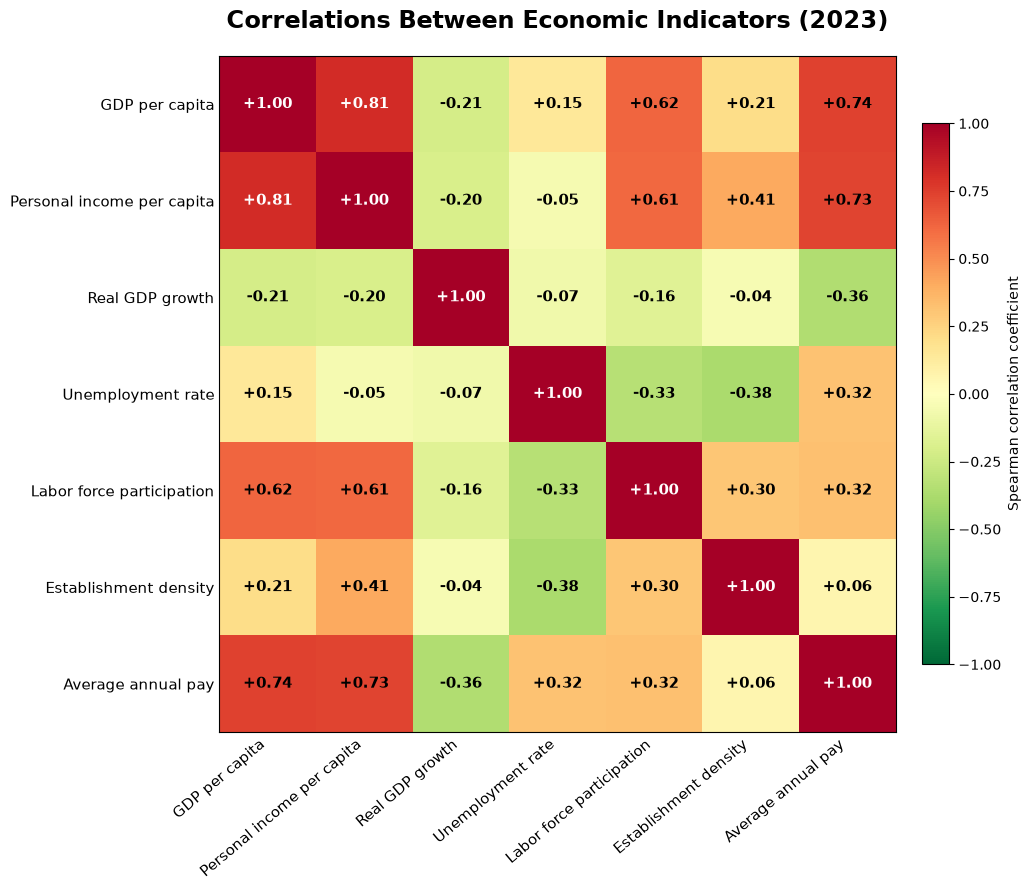

In [46]:
# Correlations between economic indicators (2023)

feature_corr = (
    data_2023[list(economic_features)]
    .corr(method="spearman")
    .rename(index=economic_features, columns=economic_features)
)

mask = np.triu(np.ones(feature_corr.shape, dtype=bool), k=1)
masked_corr = feature_corr.values

fig, ax = plt.subplots(figsize=(11, 9))

cmap = plt.get_cmap("RdYlGn_r").copy()
cmap.set_bad(color="white")

im = ax.imshow(
    masked_corr,
    cmap=cmap,
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(feature_corr.columns)))
ax.set_xticklabels(
    feature_corr.columns,
    rotation=40,
    ha="right",
    fontsize=11
)

ax.set_yticks(range(len(feature_corr.index)))
ax.set_yticklabels(feature_corr.index, fontsize=11)

for i in range(len(feature_corr)):
    for j in range(len(feature_corr)):
        value = feature_corr.iloc[i, j]

        ax.text(
            j, i, f"{value:+.2f}",
            ha="center",
            va="center",
            fontsize=11,
            fontweight="bold",
            color="white" if abs(value) >= 0.75 else "black"
        )

ax.set_title(
    "Correlations Between Economic Indicators (2023)",
    fontsize=17,
    fontweight="bold",
    pad=20
)

cbar = fig.colorbar(im, ax=ax, shrink=0.8, pad=0.03)
cbar.set_label("Spearman correlation coefficient")

ax.tick_params(length=0)
plt.tight_layout()

fig.savefig(
    STATIC_DIR / "05_18_economic_indicators_correlation_matrix_2023.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



**Key findings:**

- GDP per capita, personal income per capita, and average annual pay are strongly positively correlated ($r_s=0.73$–$0.81$), suggesting substantial overlap between economic development indicators.
- Labor force participation is moderately associated with GDP per capita ($r_s=0.62$).
- Real GDP growth is weakly negatively associated with GDP per capita ($r_s=-0.21$), indicating that economic size per resident and annual growth capture different aspects of economic activity.

These relationships will be considered when selecting predictors for subsequent multivariable analysis, particularly because correlated indicators may introduce *multicollinearity*.


In [47]:
# Temporary cell: interactive bubble chart for 2023

import pandas as pd
import plotly.express as px

# izberi leto
year_selected = 2023

# pripravi podatke
plot_df = panel.loc[panel["year"] == year_selected].copy()

# odstrani vrstice z manjkajočimi vrednostmi v potrebnih stolpcih
plot_df = plot_df.dropna(subset=[
    "state",
    "gdp_per_capita",
    "personal_income_per_capita",
    "real_gdp_growth_pct",
    "incidents_per_100k"
])

# za lepši prikaz v hoverju
plot_df["gdp_per_capita_k"] = plot_df["gdp_per_capita"] / 1000
plot_df["personal_income_per_capita_k"] = plot_df["personal_income_per_capita"] / 1000

fig = px.scatter(
    plot_df,
    x="gdp_per_capita",
    y="personal_income_per_capita",
    size="incidents_per_100k",
    color="real_gdp_growth_pct",
    hover_name="state",
    hover_data={
        "gdp_per_capita": ":,.0f",
        "personal_income_per_capita": ":,.0f",
        "real_gdp_growth_pct": ":.2f",
        "incidents_per_100k": ":.3f",
        "incident_count": True,
        "population": ":,.0f"
    },
    title="Economic Indicators and Cyber Incident Rates by State (2023)",
    labels={
        "gdp_per_capita": "GDP per capita (USD)",
        "personal_income_per_capita": "Personal income per capita (USD)",
        "real_gdp_growth_pct": "Real GDP growth (%)",
        "incidents_per_100k": "Incidents per 100,000 residents"
    }
)

fig.update_traces(marker=dict(line=dict(width=1, color="white")), opacity=0.8)

fig.update_layout(
    title=dict(font=dict(size=24)),
    xaxis_title="GDP per capita (USD)",
    yaxis_title="Personal income per capita (USD)",
    legend_title="Real GDP growth (%)",
    template="plotly_white",
    width=1100,
    height=700
)

fig.show()


### Sector-level economic analysis

Documented cybersecurity incidents are aggregated by state, year, and target industry, then merged with state-level economic indicators.

The resulting dataset enables comparisons of economic conditions and sector-specific incident rates across US states from 2014 to 2025. Sectors with zero documented incidents are retained.


In [48]:
# Prepare sector-level state-year economic panel

sector_incidents = (
    umd_period.loc[umd_period["matched_state"]]
    .groupby(["state", "year", "industry"])
    .size()
    .reset_index(name="sector_incident_count")
)

# Use a stable set of sectors across all years
industries = sorted(
    umd_period.loc[
        umd_period["matched_state"], "industry"
    ].dropna().unique()
)

# Create all state-year-sector combinations
sector_panel = (
    panel[["state", "year"]]
    .merge(pd.DataFrame({"industry": industries}), how="cross")
    .merge(
        sector_incidents,
        on=["state", "year", "industry"],
        how="left",
        validate="one_to_one"
    )
)

sector_panel["sector_incident_count"] = (
    sector_panel["sector_incident_count"]
    .fillna(0)
    .astype(int)
)

# Add economic indicators and population
sector_panel = sector_panel.merge(
    panel,
    on=["state", "year"],
    how="left",
    validate="many_to_one"
)

# Sector incidents per 100,000 state residents
sector_panel["sector_incidents_per_100k"] = (
    sector_panel["sector_incident_count"]
    / sector_panel["population"]
    * 100_000
)

# Data validation
assert (
    sector_panel["sector_incident_count"].sum()
    == panel["incident_count"].sum()
), "Sector totals do not match the original incident counts."

assert not sector_panel.duplicated(
    ["state", "year", "industry"]
).any()

print(f"Sectors: {len(industries)}")
print(f"State-year-sector observations: {len(sector_panel):,}")
print(f"Total incidents: {sector_panel['sector_incident_count'].sum():,}")
print(f"Zero-incident observations: {(sector_panel['sector_incident_count'] == 0).sum():,}")

display(
    sector_panel[
        [
            "state", "year", "industry",
            "sector_incident_count",
            "sector_incidents_per_100k",
            "gdp_per_capita",
            "personal_income_per_capita",
            "unemployment_rate",
            "real_gdp_growth_pct"
        ]
    ].head(10)
)


Sectors: 21
State-year-sector observations: 12,600
Total incidents: 6,195
Zero-incident observations: 10,069


,state,year,industry,sector_incident_count,sector_incidents_per_100k,gdp_per_capita,personal_income_per_capita,unemployment_rate,real_gdp_growth_pct
0,Alabama,2014,Accommodation and Food Services,0,0.000000,40317.961797,36710.0,6.8,-0.43143
1,Alabama,2014,Administrative and Support and Waste Managemen...,0,0.000000,40317.961797,36710.0,6.8,-0.43143
2,Alabama,2014,"Agriculture, Forestry, Fishing and Hunting",0,0.000000,40317.961797,36710.0,6.8,-0.43143
3,Alabama,2014,"Arts, Entertainment, and Recreation",0,0.000000,40317.961797,36710.0,6.8,-0.43143
4,Alabama,2014,Construction,0,0.000000,40317.961797,36710.0,6.8,-0.43143
5,Alabama,2014,Educational Services,1,0.020459,40317.961797,36710.0,6.8,-0.43143
6,Alabama,2014,Finance and Insurance,0,0.000000,40317.961797,36710.0,6.8,-0.43143
7,Alabama,2014,Health Care and Social Assistance,0,0.000000,40317.961797,36710.0,6.8,-0.43143
8,Alabama,2014,Information,0,0.000000,40317.961797,36710.0,6.8,-0.43143
9,Alabama,2014,Management of Companies and Enterprises,0,0.000000,40317.961797,36710.0,6.8,-0.43143


findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


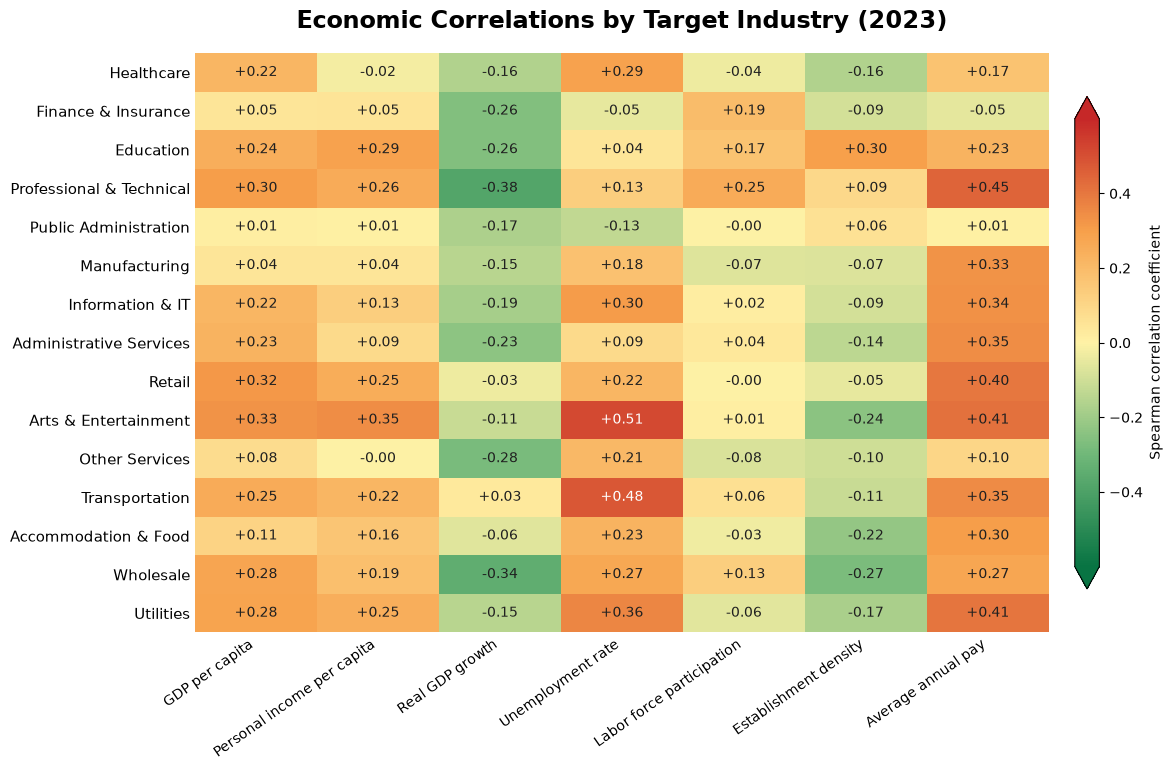

In [52]:

# Sector-specific economic correlations (2023) — improved heatmap

from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

# Short labels for visualization only
industry_aliases = {
    "Health Care and Social Assistance": "Healthcare",
    "Finance and Insurance": "Finance & Insurance",
    "Educational Services": "Education",
    "Professional, Scientific, and Technical Services": "Professional & Technical",
    "Public Administration": "Public Administration",
    "Manufacturing": "Manufacturing",
    "Information": "Information & IT",
    "Administrative and Support and Waste Management and Remediation Services": "Administrative Services",
    "Retail Trade": "Retail",
    "Arts, Entertainment, and Recreation": "Arts & Entertainment",
    "Other Services (except Public Administration)": "Other Services",
    "Transportation and Warehousing": "Transportation",
    "Accommodation and Food Services": "Accommodation & Food",
    "Wholesale Trade": "Wholesale",
    "Utilities": "Utilities"
}

heatmap_data = sector_corr.pivot(
    index="industry",
    columns="economic_factor",
    values="correlation"
)

sector_order = (
    sector_corr.groupby("industry")["total_incidents"]
    .first()
    .sort_values(ascending=False)
    .index
)

heatmap_data = heatmap_data.reindex(
    index=sector_order,
    columns=list(economic_features.values())
)

heatmap_data.index = [
    industry_aliases.get(industry, industry)
    for industry in heatmap_data.index
]

# High-contrast green → yellow → red palette
cmap = LinearSegmentedColormap.from_list(
    "sector_correlation",
    [
        "#087443",
        "#70B879",
        "#FFF2A6",
        "#F7A04B",
        "#C62828"
    ],
    N=256
)

fig, ax = plt.subplots(
    figsize=(12.5, max(6, len(heatmap_data) * 0.52))
)

im = ax.imshow(
    heatmap_data.values,
    cmap=cmap,
    norm=TwoSlopeNorm(vmin=-0.6, vcenter=0, vmax=0.6),
    aspect="auto"
)

ax.set_xticks(range(len(heatmap_data.columns)))
ax.set_xticklabels(
    heatmap_data.columns,
    rotation=35,
    ha="right",
    fontsize=10
)

ax.set_yticks(range(len(heatmap_data.index)))
ax.set_yticklabels(
    heatmap_data.index,
    fontsize=11
)

for i in range(len(heatmap_data.index)):
    for j in range(len(heatmap_data.columns)):
        value = heatmap_data.iloc[i, j]

        if pd.notna(value):
            ax.text(
                j, i,
                f"{value:+.2f}",
                ha="center",
                va="center",
                fontsize=10,
                fontweight="medium",
                color="white" if abs(value) >= 0.45 else "#202020"
            )

ax.set_title(
    "Economic Correlations by Target Industry (2023)",
    fontsize=17,
    fontweight="bold",
    pad=18
)

ax.tick_params(length=0)
ax.spines[:].set_visible(False)

cbar = fig.colorbar(
    im,
    ax=ax,
    shrink=0.85,
    pad=0.025,
    extend="both"
)

cbar.set_label("Spearman correlation coefficient")

plt.tight_layout()

fig.savefig(
    STATIC_DIR / "05_19_sector_economic_correlations_heatmap_2023.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [55]:
# =========================
# PRIPRAVA PODATKOV
# =========================

panel = sector_panel.copy()   # <- če imaš drugo ime, zamenjaj tukaj

year_selected = 2023
top_n_industries = 15

factor_cols = [
    "gdp_per_capita",
    "personal_income_per_capita",
    "real_gdp_growth_pct",
    "unemployment_rate",
    "labor_force_participation_rate",
    "establishments_per_10k",
    "qcew_avg_annual_pay"
]

factor_labels = {
    "gdp_per_capita": "GDP per capita",
    "personal_income_per_capita": "Personal income per capita",
    "real_gdp_growth_pct": "Real GDP growth",
    "unemployment_rate": "Unemployment rate",
    "labor_force_participation_rate": "Labor force participation",
    "establishments_per_10k": "Establishment density",
    "qcew_avg_annual_pay": "Average annual pay"
}

industry_alias = {
    "Health Care and Social Assistance": "Healthcare",
    "Finance and Insurance": "Finance & Insurance",
    "Educational Services": "Education",
    "Professional, Scientific, and Technical Services": "Professional & Technical",
    "Public Administration": "Public Administration",
    "Manufacturing": "Manufacturing",
    "Information": "Information & IT",
    "Administrative and Support and Waste Management and Remediation Services": "Administrative Services",
    "Retail Trade": "Retail",
    "Arts, Entertainment, and Recreation": "Arts & Entertainment",
    "Other Services (except Public Administration)": "Other Services",
    "Transportation and Warehousing": "Transportation",
    "Accommodation and Food Services": "Accommodation & Food",
    "Wholesale Trade": "Wholesale",
    "Utilities": "Utilities",
    "Construction": "Construction",
    "Real Estate and Rental and Leasing": "Real Estate",
    "Management of Companies and Enterprises": "Management",
    "Agriculture, Forestry, Fishing and Hunting": "Agriculture",
    "Mining, Quarrying, and Oil and Gas Extraction": "Mining & Oil",
    "Undetermined": "Undetermined"
}

panel["industry_short"] = panel["industry"].replace(industry_alias)

# top sektorji po skupnem številu incidentov v izbranem letu
top_industries = (
    panel.loc[panel["year"] == year_selected]
         .groupby("industry_short")["sector_incident_count"]
         .sum()
         .sort_values(ascending=False)
         .head(top_n_industries)
         .index
         .tolist()
)

panel_top = panel[panel["industry_short"].isin(top_industries)].copy()

print("Selected year:", year_selected)
print("Top industries used:", len(top_industries))
print(top_industries)

Selected year: 2023
Top industries used: 15
['Healthcare', 'Finance & Insurance', 'Education', 'Professional & Technical', 'Public Administration', 'Manufacturing', 'Information & IT', 'Administrative Services', 'Retail', 'Arts & Entertainment', 'Other Services', 'Transportation', 'Accommodation & Food', 'Wholesale', 'Utilities']


In [57]:

# Compact interactive sector correlation heatmap

years = sorted(corr_long["year"].unique())

def get_matrix(year):
    return (
        corr_long.loc[corr_long["year"] == year]
        .pivot(index="industry_short", columns="factor", values="spearman_r")
        .reindex(index=industry_order, columns=factor_order)
    )

initial_year = 2023
initial_matrix = get_matrix(initial_year)

colorscale = [
    [0.00, "#087443"],
    [0.25, "#70B879"],
    [0.50, "#FFF2A6"],
    [0.75, "#F7A04B"],
    [1.00, "#C62828"]
]

fig = go.Figure(
    go.Heatmap(
        z=initial_matrix.values,
        x=factor_order,
        y=industry_order,
        colorscale=colorscale,
        zmin=-0.6,
        zmax=0.6,
        zmid=0,
        colorbar=dict(
            title="Spearman ρ",
            thickness=15,
            len=0.8
        ),
        hovertemplate=(
            "Industry: %{y}<br>"
            "Factor: %{x}<br>"
            "Spearman ρ: %{z:.3f}"
            "<extra></extra>"
        )
    )
)

buttons = [
    dict(
        label=str(year),
        method="update",
        args=[
            {"z": [get_matrix(year).values]},
            {"title.text": f"Economic Correlations by Industry ({year})"}
        ]
    )
    for year in years
]

fig.update_layout(
    title=dict(
        text=f"Economic Correlations by Industry ({initial_year})",
        x=0.5,
        font=dict(size=20)
    ),
    width=1050,
    height=650,
    margin=dict(l=180, r=80, t=115, b=120),
    template="plotly_white",
    xaxis=dict(
        tickangle=-35,
        tickfont=dict(size=11),
        side="bottom"
    ),
    yaxis=dict(
        autorange="reversed",
        tickfont=dict(size=11)
    ),
    updatemenus=[
        dict(
            type="dropdown",
            buttons=buttons,
            direction="down",
            x=0.02,
            y=1.11,
            xanchor="left",
            yanchor="top",
            showactive=True,
            bgcolor="white",
            bordercolor="#D5D5D5",
            font=dict(size=12)
        )
    ]
)

fig.write_html(
    INTERACTIVE_DIR / "05_20_sector_correlations_interactive.html",
    include_plotlyjs=True
)

fig.show()
